# This notebook covers deep learnnig models

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import os
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


### 1. Load datasets

In [3]:
X_train_scaled = np.load("../data/processed/X_train_scaled.npy")
X_test_scaled  = np.load("../data/processed/X_test_scaled.npy")
y_train_scaled = np.load("../data/processed/y_train_scaled.npy")
y_test_scaled  = np.load("../data/processed/y_test_scaled.npy")

print("X_train:", X_train_scaled.shape)
print("X_test :", X_test_scaled.shape)

X_train: (15759, 24)
X_test : (3940, 24)


### 2. Create Sequences

In [4]:
def create_sequences(X, y, time_steps=10):
    Xs, ys = [], []
    for i in range(len(X) - time_steps):
        Xs.append(X[i:i+time_steps])
        ys.append(y[i+time_steps])
    return np.array(Xs), np.array(ys)

TIME_STEPS = 10

X_train_seq, y_train_seq = create_sequences(X_train_scaled, y_train_scaled, TIME_STEPS)
X_test_seq, y_test_seq   = create_sequences(X_test_scaled, y_test_scaled, TIME_STEPS)

print("Train sequence shape:", X_train_seq.shape)
print("Test sequence shape :", X_test_seq.shape)

Train sequence shape: (15749, 10, 24)
Test sequence shape : (3930, 10, 24)


### 3. Create PyTorch Dataset & DataLoader

In [6]:
class TimeSeriesDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
    
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


train_dataset = TimeSeriesDataset(X_train_seq, y_train_seq)
test_dataset  = TimeSeriesDataset(X_test_seq, y_test_seq)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=64, shuffle=False)

### 4. Define LSTM model 

In [9]:
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size1=64, hidden_size2=32, dropout=0.2):
        super(LSTMModel, self).__init__()
        
        self.lstm1 = nn.LSTM(input_size, hidden_size1, batch_first=True)
        self.lstm2 = nn.LSTM(hidden_size1, hidden_size2, batch_first=True)
        
        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(hidden_size2, 16)
        self.fc2 = nn.Linear(16, 1)
        self.relu = nn.ReLU()
    
    def forward(self, x):
        out, _ = self.lstm1(x)
        out = self.dropout(out)
        
        out, _ = self.lstm2(out)
        out = out[:, -1, :]          # Take last time step
        out = self.dropout(out)
        
        out = self.relu(self.fc1(out))
        out = self.fc2(out)
        return out


input_size = X_train_seq.shape[2]
model = LSTMModel(input_size=input_size).to(device)

print(model)

LSTMModel(
  (lstm1): LSTM(24, 64, batch_first=True)
  (lstm2): LSTM(64, 32, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc1): Linear(in_features=32, out_features=16, bias=True)
  (fc2): Linear(in_features=16, out_features=1, bias=True)
  (relu): ReLU()
)


### 5. Loss Function, Optimizer & Regularization

In [12]:
criterion = nn.MSELoss()                    # Loss function for regression
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Learning rate scheduler (regularization)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=5
)

### 6. Training Loop

In [23]:
epochs = 50
patience = 10          # Stop if no improvement for 10 epochs
best_val_loss = float('inf')
patience_counter = 0
best_model_state = None

train_losses = []
val_losses = []

for epoch in range(epochs):
    # Training 
    model.train()
    train_loss = 0.0
    
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        
        optimizer.zero_grad()
        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
    
    train_loss /= len(train_loader)
    train_losses.append(train_loss)
    
    #  Validation 
    model.eval()
    val_loss = 0.0
    
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            val_loss += loss.item()
    
    val_loss /= len(test_loader)
    val_losses.append(val_loss)
    
    # Update learning rate scheduler
    scheduler.step(val_loss)
    
    print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f}")
    
    # Early Stopping 
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = model.state_dict()
        patience_counter = 0
        print("  → Validation loss improved. Model saved.")
    else:
        patience_counter += 1
        print(f"  → No improvement. Patience: {patience_counter}/{patience}")
        
        if patience_counter >= patience:
            print("Early stopping triggered!")
            break

# Load best model weights
if best_model_state is not None:
    model.load_state_dict(best_model_state)
    print("\nBest model weights loaded.")

Epoch [1/50] | Train Loss: 0.005527 | Val Loss: 0.004819
  → Validation loss improved. Model saved.
Epoch [2/50] | Train Loss: 0.005540 | Val Loss: 0.004862
  → No improvement. Patience: 1/10
Epoch [3/50] | Train Loss: 0.005528 | Val Loss: 0.004850
  → No improvement. Patience: 2/10
Epoch [4/50] | Train Loss: 0.005519 | Val Loss: 0.004829
  → No improvement. Patience: 3/10
Epoch [5/50] | Train Loss: 0.005482 | Val Loss: 0.004804
  → Validation loss improved. Model saved.
Epoch [6/50] | Train Loss: 0.005471 | Val Loss: 0.004807
  → No improvement. Patience: 1/10
Epoch [7/50] | Train Loss: 0.005452 | Val Loss: 0.004801
  → Validation loss improved. Model saved.
Epoch [8/50] | Train Loss: 0.005475 | Val Loss: 0.004798
  → Validation loss improved. Model saved.
Epoch [9/50] | Train Loss: 0.005458 | Val Loss: 0.004797
  → Validation loss improved. Model saved.
Epoch [10/50] | Train Loss: 0.005430 | Val Loss: 0.004797
  → Validation loss improved. Model saved.
Epoch [11/50] | Train Loss: 0.0

### 7. Plot Training History

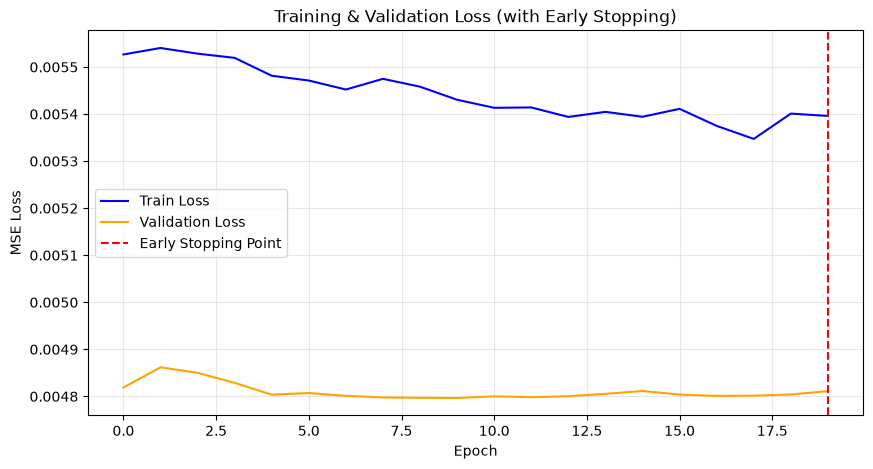

In [33]:
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="Train Loss", color="blue")
plt.plot(val_losses, label="Validation Loss", color="orange")
plt.axvline(x=len(train_losses)-1, color='red', linestyle='--', label="Early Stopping Point")
plt.title("Training & Validation Loss (with Early Stopping)")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 8. Evaluation

In [ ]:
model.eval()
y_preds = []
y_trues = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        pred = model(X_batch).cpu().numpy()
        
        y_preds.extend(pred)
        y_trues.extend(y_batch.numpy())

# Convert to numpy arrays
y_preds = np.array(y_preds).flatten()
y_trues = np.array(y_trues).flatten()

# Calculate metrics
mae  = mean_absolute_error(y_trues, y_preds)
rmse = np.sqrt(mean_squared_error(y_trues, y_preds))
r2   = r2_score(y_trues, y_preds)

print("PyTorch LSTM Results:")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

PyTorch LSTM Results:
MAE  : 0.0362
RMSE : 0.0690
R²   : 0.3058


### 9. Inference

<Figure size 1400x500 with 0 Axes>

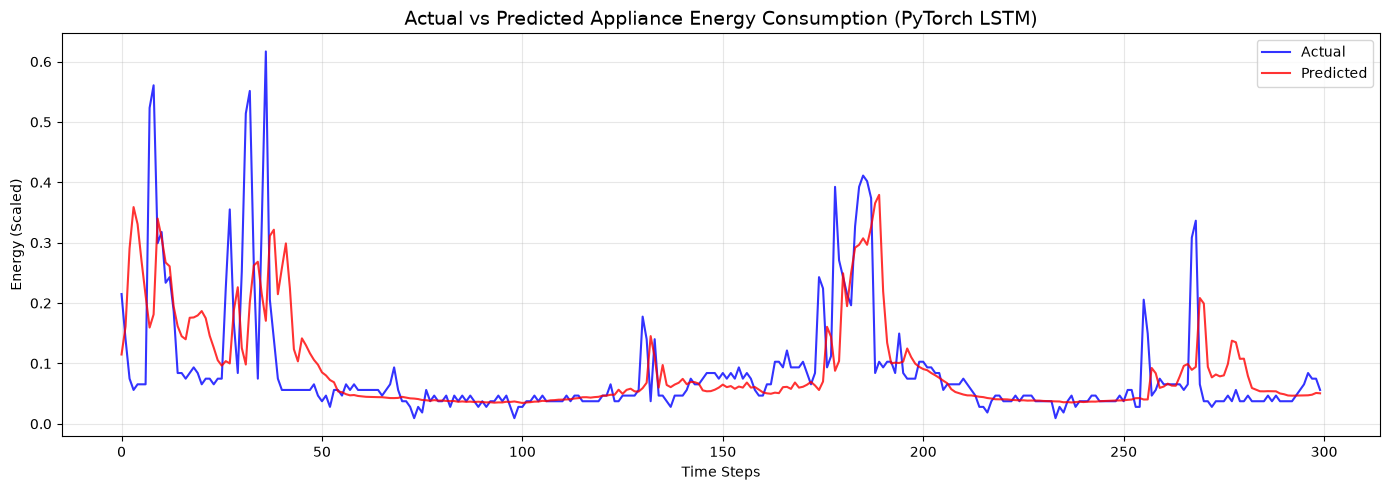

In [ ]:
plt.figure(figsize=(14, 5))

plt.figure(figsize=(14, 5))

plt.plot(y_trues[:300], label="Actual", color="blue", alpha=0.8, linewidth=1.5)
plt.plot(y_preds[:300], label="Predicted", color="red", alpha=0.8, linewidth=1.5)

plt.title("Actual vs Predicted Appliance Energy Consumption (PyTorch LSTM)", fontsize=14)
plt.xlabel("Time Steps")
plt.ylabel("Energy (Scaled)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 10. Save model

In [34]:
os.makedirs("../models", exist_ok=True)

torch.save(model.state_dict(), "../models/lstm_pytorch_model.pth")
print("Model saved successfully at: models/lstm_pytorch_model.pth")

Model saved successfully at: models/lstm_pytorch_model.pth
